# Importance des variables : pourquoi la mesure standard est fausse, et comment la réparer

> **Version de travail.** Les parties 1 à 11 sont rédigées et tournent. La partie 12 attend la
> fin des expériences.

**Ce notebook ne suppose aucune connaissance préalable.** On part de zéro : ce qu'est un arbre de
décision, ce qu'il mesure, pourquoi sa mesure d'importance est biaisée, et les deux remèdes que ce
projet combine.

Chaque idée est montrée, pas seulement décrite : tout le code tourne, toutes les figures sont
produites par les cellules.

> **Pour exécuter** : lancez depuis la racine du dépôt (`jupyter lab notebooks/cours_wip.ipynb`).
> Dépendances : `numpy`, `scipy`, `scikit-learn`, `pandas`, `matplotlib`.

---

## Plan

| | |
|---|---|
| 1 | La question qu'on se pose |
| 2 | Un arbre de décision, construit pas à pas |
| 3 | L'impureté : la seule chose que l'arbre optimise |
| 4 | Le MDI, mesure d'importance standard |
| 5 | **Le bug** : de l'importance venue de nulle part |
| 6 | Pourquoi : une identité en trois lignes |
| 7 | Le second biais : juger sur sa propre copie |
| 8 | Remède 1 : mesurer sur des données non vues |
| 9 | Remède 2 : élaguer l'arbre |
| 10 | Comment on sait qui a raison (et les scénarios disponibles) |
| 11 | Le plan d'expérience |
| 12 | Ce qu'on a trouvé |

In [379]:
import sys, warnings
from pathlib import Path

# marche qu'on lance depuis la racine du depot ou depuis notebooks/
racine = Path.cwd()
while not (racine / "src" / "simulate.py").exists() and racine != racine.parent:
    racine = racine.parent
sys.path.insert(0, str(racine / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# palette unique pour tout le notebook
INK, SOFT, GRID = "#16191f", "#4e545f", "#dfe2e9"
BLEU, ORANGE, VERT, PRUNE = "#2a78d6", "#eb6834", "#1baf7a", "#3a4a86"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": SOFT, "text.color": INK,
    "xtick.color": SOFT, "ytick.color": SOFT, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.dpi": 110,
})
print("prêt")

prêt


---
## 1. La question qu'on se pose

Vous avez un tableau. Chaque ligne est une observation, chaque colonne une **variable**, et une
colonne à part — notée $y$ — est ce qu'on cherche à **prédire**.

Exemple : des quartiers de Californie. On connaît le revenu médian, l'âge des maisons, le nombre de
pièces… et on veut prédire le **prix médian** du quartier.

| quartier | revenu | âge | pièces | → | **prix** |
|---|---|---|---|---|---|
| A | 1,5 | 40 | 4,2 | | **80 k\$** |
| B | 6,0 | 20 | 7,1 | | **350 k\$** |

Une fois qu'un modèle prédit correctement, une seconde question arrive, souvent plus intéressante
que la prédiction elle-même :

> **Quelles variables comptent vraiment ?**

C'est l'*importance des variables*. Elle sert à comprendre un phénomène, à éliminer des mesures
coûteuses et inutiles, ou à vérifier qu'un modèle ne s'appuie pas sur n'importe quoi.

Ce notebook montre que la mesure la plus utilisée pour ça est **fausse**, de deux manières
indépendantes — et ce qu'on peut y faire.

---
## 2. Un arbre de décision, construit pas à pas

Un arbre pose des questions binaires sur les variables et découpe les données en groupes.

Fabriquons un jeu minuscule : le prix dépend du revenu, et **rien d'autre**.

In [380]:
revenu = np.array([1.5, 1.8, 2.0, 6.0, 6.5, 7.0])
age    = np.array([40, 35, 18, 20, 25, 15], dtype=float)   # sans rapport avec le prix
prix   = np.array([80, 95, 110, 350, 380, 400], dtype=float)

print(f"{'quartier':>9} {'revenu':>7} {'age':>5} {'prix':>6}")
for q, r_, a_, p_ in zip("ABCDEF", revenu, age, prix):
    print(f"{q:>9} {r_:>7.1f} {a_:>5.0f} {p_:>6.0f}")
print(f"\nmoyenne des prix : {prix.mean():.0f} k$")

 quartier  revenu   age   prix
        A     1.5    40     80
        B     1.8    35     95
        C     2.0    18    110
        D     6.0    20    350
        E     6.5    25    380
        F     7.0    15    400

moyenne des prix : 236 k$


L'arbre cherche **une question** qui sépare au mieux les prix. Supposons pour l'instant que
« revenu ≤ 4 ? » est cette question (on **prouvera** que c'est le bon choix dans la partie 3) —
voyons ce que donne cette coupure, moyenne par moyenne.

In [381]:
# les moyennes sont calculees ici, pas inventees : c'est la preuve que le dessin
# ci-dessous correspond vraiment aux 6 chiffres du tableau precedent
m_tout    = prix.mean()
m_gauche  = prix[:3].mean()   # A, B, C : revenu <= 4
m_droite  = prix[3:].mean()   # D, E, F : revenu >  4
print(f"moyenne globale      : {m_tout:.0f} k$")
print(f"moyenne revenu <= 4  : {m_gauche:.0f} k$  (A, B, C)")
print(f"moyenne revenu >  4  : {m_droite:.0f} k$  (D, E, F)")

moyenne globale      : 236 k$
moyenne revenu <= 4  : 95 k$  (A, B, C)
moyenne revenu >  4  : 377 k$  (D, E, F)


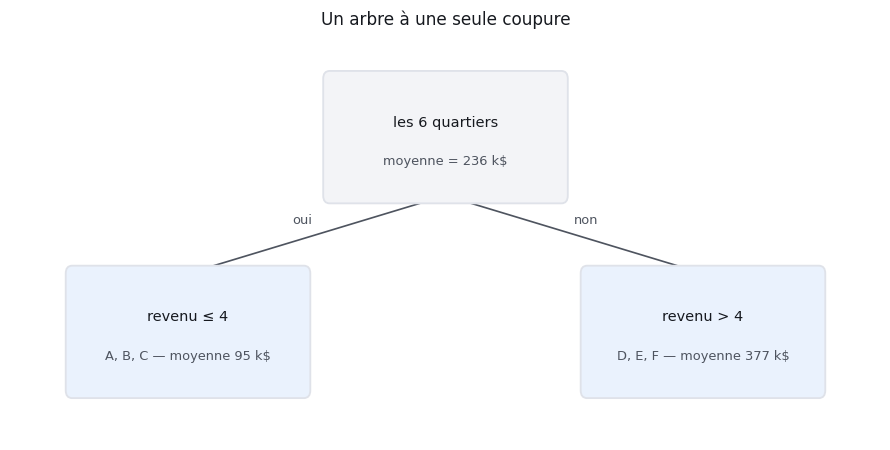

In [382]:
fig, ax = plt.subplots(figsize=(8.2, 4.2))

def boite(x, y, titre, detail, couleur):
    ax.add_patch(FancyBboxPatch((x - .72, y - .30), 1.44, .60,
                 boxstyle="round,pad=0.04", fc=couleur, ec=GRID, lw=1.2, zorder=3))
    ax.text(x, y + .08, titre, ha="center", va="center", fontsize=9.5, color=INK, zorder=4)
    ax.text(x, y - .12, detail, ha="center", va="center", fontsize=8.5, color=SOFT, zorder=4)

boite(0, 1.0, "les 6 quartiers", f"moyenne = {m_tout:.0f} k$", "#f3f4f7")
boite(-1.6, 0, "revenu ≤ 4", f"A, B, C — moyenne {m_gauche:.0f} k$", "#eaf2fd")
boite( 1.6, 0, "revenu > 4", f"D, E, F — moyenne {m_droite:.0f} k$", "#eaf2fd")
for dx in (-1.6, 1.6):
    ax.plot([0, dx], [0.70, 0.30], color=SOFT, lw=1.1, zorder=1)
ax.text(-0.95, .56, "oui", fontsize=8.5, color=SOFT)
ax.text( 0.80, .56, "non", fontsize=8.5, color=SOFT)
ax.set_xlim(-2.7, 2.7); ax.set_ylim(-.55, 1.5); ax.axis("off")
ax.set_title("Un arbre à une seule coupure", fontsize=11, color=INK, pad=10)
plt.tight_layout(); plt.show()

**Le vocabulaire, une fois pour toutes :**

- un **nœud** est un groupe de lignes ; la **racine** contient tout le monde ;
- une **coupure** envoie chaque ligne à gauche ou à droite selon une question ;
- une **feuille** est un nœud qu'on ne coupe plus ;
- pour **prédire**, on fait descendre la nouvelle ligne et on répond **la moyenne de sa feuille**.

Un nouveau quartier avec un revenu de 1,9 part à gauche → prédiction = 95 k\$.

Le point essentiel : **un nœud contient des lignes, pas des variables.**

---
## 3. L'impureté : la seule chose que l'arbre optimise

Comment l'arbre a-t-il *su* que « revenu ≤ 4 » était une bonne question ?

Il mesure à quel point les prix sont **mélangés** dans un groupe. Cette mesure s'appelle
l'**impureté**, et en régression c'est simplement la **variance** :

$$H(\text{nœud}) = \text{moyenne des } (y_i - \bar{y}_{\text{nœud}})^2$$

- prix tous proches → impureté **faible** (groupe homogène) ;
- prix dispersés → impureté **élevée** ;
- tous identiques → impureté **nulle**, le nœud est dit *pur*.

In [383]:
def impurete(v):
    return float(np.mean((v - v.mean())**2))

gauche, droite = prix[:3], prix[3:]
H_avant = impurete(prix)
H_apres = (len(gauche)/len(prix))*impurete(gauche) + (len(droite)/len(prix))*impurete(droite)

print(f"impureté AVANT la coupure : {H_avant:8.1f}")
print(f"impureté APRÈS (pondérée) : {H_apres:8.1f}") # pondéré par nb de points dans chaque noeud
print(f"{'':>26} {'-'*8}")
print(f"baisse d'impureté         : {H_avant - H_apres:8.1f}   <- le gain de cette coupure") #ce que sklearn optimise en interne

impureté AVANT la coupure :  20120.1
impureté APRÈS (pondérée) :    286.1
                           --------
baisse d'impureté         :  19834.0   <- le gain de cette coupure


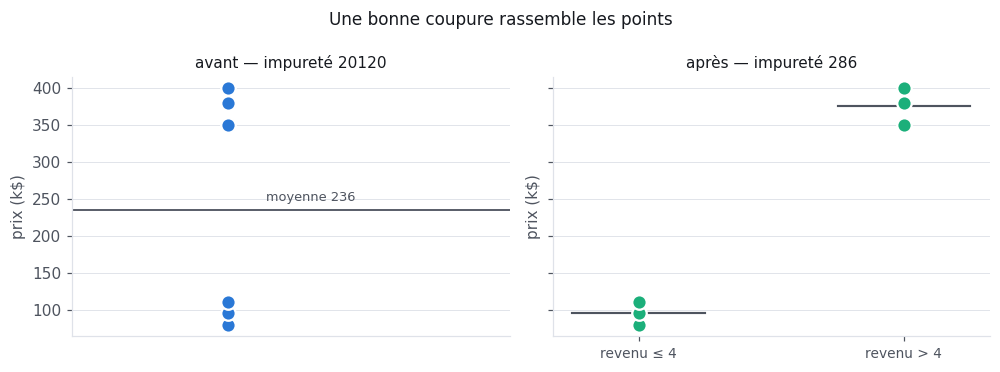

In [384]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4), sharey=True)

axes[0].scatter(np.zeros(6), prix, s=90, color=BLEU, zorder=3, edgecolor="white", lw=1.5)
axes[0].axhline(prix.mean(), color=SOFT, lw=1.2, ls="-")
axes[0].text(.12, prix.mean()+12, f"moyenne {prix.mean():.0f}", fontsize=8.5, color=SOFT)
axes[0].set_title(f"avant — impureté {H_avant:.0f}", fontsize=10)
axes[0].set_xlim(-.5, .9); axes[0].set_xticks([])

for i, (grp, lab) in enumerate([(gauche, "revenu ≤ 4"), (droite, "revenu > 4")]):
    axes[1].scatter(np.full(len(grp), i), grp, s=90, color=VERT, zorder=3,
                    edgecolor="white", lw=1.5)
    axes[1].plot([i-.25, i+.25], [grp.mean()]*2, color=SOFT, lw=1.4)
axes[1].set_title(f"après — impureté {H_apres:.0f}", fontsize=10)
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["revenu ≤ 4", "revenu > 4"], fontsize=9)

for a in axes:
    a.grid(axis="y"); a.set_ylabel("prix (k$)")
fig.suptitle("Une bonne coupure rassemble les points", fontsize=11, color=INK)
plt.tight_layout(); plt.show()

**L'algorithme complet tient en une phrase :** essayer toutes les variables et tous les seuils,
garder la coupure qui fait le plus baisser l'impureté, puis recommencer dans chaque moitié.

Une remarque qui servira beaucoup plus loin : **une coupure ne peut jamais faire *monter*
l'impureté.** Dans le pire des cas elle ne change rien. Donc le gain est toujours ≥ 0 —
**même pour une coupure sur une variable complètement inutile.**

**Reste une question qu'on n'a pas encore posée : comment l'arbre *trouve*-t-il « revenu ≤ 4 » ?**
On ne l'a pas encore montré — jusqu'ici on a seulement vérifié que cette coupure précise est bonne,
pas qu'elle est la **meilleure** parmi toutes les possibles. Codons la recherche en entier, sans
scikit-learn.

In [385]:
def meilleure_coupure(X, y):
    '''Essaie chaque variable et chaque seuil candidat, garde le gain d'impureté le plus grand.'''
    meilleur_gain, meilleure_var, meilleur_seuil = -1.0, None, None
    for var in range(X.shape[1]):
        valeurs = np.unique(X[:, var])
        seuils = (valeurs[:-1] + valeurs[1:]) / 2        # un seuil entre chaque paire de voisins
        for s in seuils:
            gauche, droite = y[X[:, var] <= s], y[X[:, var] > s]
            apres = (gauche.size/y.size)*impurete(gauche) + (droite.size/y.size)*impurete(droite)
            gain = impurete(y) - apres
            if gain > meilleur_gain:
                meilleur_gain, meilleure_var, meilleur_seuil = gain, var, s
    return meilleure_var, meilleur_seuil, meilleur_gain

X = np.column_stack([revenu, age])
var, seuil, gain = meilleure_coupure(X, prix)
print(f"variable choisie parmi {X.shape[1]} : {['revenu', 'age'][var]}")
print(f"seuil choisi (parmi {np.unique(X[:,0]).size - 1} seuils testés sur le revenu seul) : {seuil:.2f}")
print(f"gain d'impureté : {gain:.1f}")

variable choisie parmi 2 : revenu
seuil choisi (parmi 5 seuils testés sur le revenu seul) : 4.00
gain d'impureté : 19834.0


C'est tout ce que fait `.fit()` **à un nœud donné**. Et "recommencer dans chaque moitié", c'est de
la récursion : on rappelle exactement la même fonction sur les lignes de gauche, puis sur celles de
droite, jusqu'à ce qu'un critère d'arrêt soit atteint (profondeur maximale, nœud déjà pur, trop peu
de lignes…). Codons aussi cette récursion :

In [386]:
def construire(X, y, profondeur, max_profondeur):
    '''La meme recherche, appelee recursivement : c'est tout l'algorithme de construction.'''
    if profondeur == max_profondeur or np.ptp(y) == 0:    # trop profond, ou le noeud est deja pur
        return {"feuille": True, "moyenne": float(y.mean()), "n": int(y.size)}
    var, seuil, gain = meilleure_coupure(X, y)
    if gain <= 0:                                          # aucune coupure n'apporte rien
        return {"feuille": True, "moyenne": float(y.mean()), "n": int(y.size)}
    masque = X[:, var] <= seuil
    return {
        "feuille": False, "variable": ["revenu", "age"][var], "seuil": round(seuil, 2),
        "gauche": construire(X[masque],  y[masque],  profondeur + 1, max_profondeur),
        "droite": construire(X[~masque], y[~masque], profondeur + 1, max_profondeur),
    }

import pprint
pprint.pprint(construire(X, prix, profondeur=0, max_profondeur=1))

{'droite': {'feuille': True, 'moyenne': 376.6666666666667, 'n': 3},
 'feuille': False,
 'gauche': {'feuille': True, 'moyenne': 95.0, 'n': 3},
 'seuil': 4.0,
 'variable': 'revenu'}


Un dictionnaire imbriqué, construit à la main, qui retrouve exactement la coupure « revenu ≤ 4 »
sans qu'on la lui ait jamais donnée. **C'est ça, construire un arbre.** `DecisionTreeRegressor.fit`
fait précisément cette recherche-puis-récursion — en Cython, donc des centaines de fois plus vite,
avec des critères d'arrêt plus riches (`min_samples_leaf`, `ccp_alpha`…), mais le même calcul.

C'est aussi pourquoi on ne peut pas afficher son code avec `inspect.getsource`, comme on l'a fait
pour `src/mdi.py` et `src/prune.py` : ces deux fichiers sont écrits en Python, mais `.fit()` est du
code compilé, invisible depuis Python.

---
## 4. Le MDI, mesure d'importance standard

L'idée est naturelle : si une variable fait beaucoup baisser l'impureté, c'est qu'elle est utile.

> **MDI d'une variable** = somme des baisses d'impureté de **toutes les coupures faites sur cette
> variable**, chacune pondérée par le nombre de lignes concernées.

MDI veut dire *Mean Decrease in Impurity*. C'est la mesure que renvoie scikit-learn sous le nom
`feature_importances_`, et de très loin la plus utilisée en pratique.

Vérifions-la sur notre petit exemple, où l'on **sait** que seul le revenu compte.

In [387]:
from sklearn.tree import DecisionTreeRegressor

arbre = DecisionTreeRegressor(max_depth=1).fit(X, prix)

print(f"seuil trouvé par scikit-learn : {arbre.tree_.threshold[0]:.2f}")
print(f"seuil trouvé à la main        : {seuil:.2f}   <- la fonction meilleure_coupure de tout à l'heure\n")

imp = arbre.tree_.compute_feature_importances(normalize=False)
for nom, v in zip(["revenu", "âge   "], imp):
    print(f"  {nom} : {v:9.1f}")
print(f"\n  variance totale des prix : {impurete(prix):9.1f}")

seuil trouvé par scikit-learn : 4.00
seuil trouvé à la main        : 4.00   <- la fonction meilleure_coupure de tout à l'heure

  revenu :   19834.0
  âge    :       0.0

  variance totale des prix :   20120.1


Parfait : tout le crédit va au revenu, l'âge obtient zéro. La mesure fait exactement ce qu'on
attend.

**Sur cet exemple.** Voyons ce qui se passe quand on laisse l'arbre grandir.

---
## 5. Le bug : de l'importance venue de nulle part

Voici l'expérience décisive. On fabrique des données où **rien n'a de rapport avec rien** :

- $y$ est du bruit pur ;
- les 5 variables sont du bruit pur ;
- aucune relation, par construction.

La bonne réponse est donc : **importance nulle pour les cinq variables.**

In [388]:
rng = np.random.default_rng(0)
X_bruit = rng.normal(size=(100, 5))      # 5 variables de bruit pur
y_bruit = rng.normal(size=100)           # y sans aucun rapport

complet = DecisionTreeRegressor(random_state=0).fit(X_bruit, y_bruit)   # arbre complet
imp = complet.tree_.compute_feature_importances(normalize=False)
#à chaque nœud, scikit-learn garde en mémoire l'impureté de ce nœud (calculée sur les lignes d'entraînement tombées dedans)

print("vérité :  0.000  pour les cinq variables\n")
for j, v in enumerate(imp):
    print(f"  variable {j} : {v:.3f}")
print(f"\n  SOMME             : {imp.sum():.3f}")
print(f"  variance de y     : {y_bruit.var():.3f}   <- identique !")
print(f"  feuilles de l'arbre : {complet.get_n_leaves()}  (pour 100 points)")

vérité :  0.000  pour les cinq variables

  variable 0 : 0.170
  variable 1 : 0.168
  variable 2 : 0.086
  variable 3 : 0.097
  variable 4 : 0.304

  SOMME             : 0.824
  variance de y     : 0.824   <- identique !
  feuilles de l'arbre : 100  (pour 100 points)


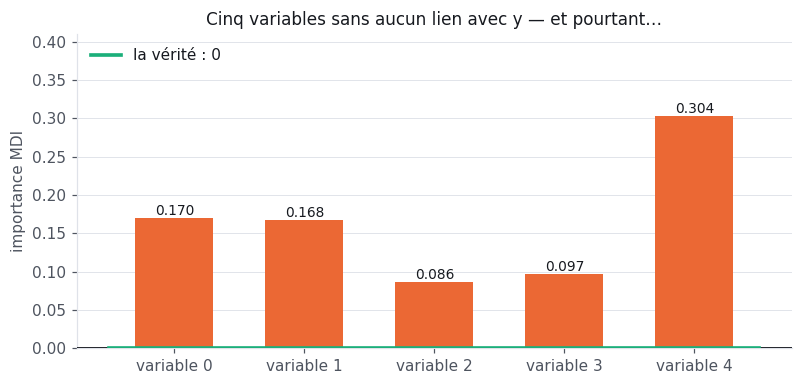

In [389]:
fig, ax = plt.subplots(figsize=(7.4, 3.6))
b = ax.bar(range(5), imp, color=ORANGE, width=.6, zorder=3)
ax.axhline(0, color=INK, lw=1.2, zorder=4)
ax.plot([-.5, 4.5], [0, 0], color=VERT, lw=2.4, zorder=5, label="la vérité : 0")
for r_, v in zip(b, imp):
    ax.text(r_.get_x()+r_.get_width()/2, v+.004, f"{v:.3f}", ha="center", fontsize=9, color=INK)
ax.set_xticks(range(5)); ax.set_xticklabels([f"variable {j}" for j in range(5)])
ax.set_ylabel("importance MDI"); ax.grid(axis="y")
ax.set_ylim(top=imp.max()*1.35)
ax.legend(frameon=False, loc="upper left")
ax.set_title("Cinq variables sans aucun lien avec y — et pourtant…", fontsize=11, color=INK)
plt.tight_layout(); plt.show()

**Chaque variable reçoit une importance franchement positive, alors que la vérité est zéro pour
toutes.** Rien dans ces données ne prédit quoi que ce soit, et la mesure affirme le contraire.

Remarquez aussi le second chiffre : la **somme des importances vaut exactement la variance de
$y$**. Ce n'est pas une coïncidence — c'est l'explication complète du phénomène.

---
## 6. Pourquoi : une identité en trois lignes

Additionnons les MDI de **toutes** les variables. Chaque nœud interne apparaît deux fois dans la
somme : une fois en positif (comme parent), une fois en négatif (comme enfant de son propre
parent). Tout ce qui est au milieu **s'annule**, et il ne reste que les extrémités :

$$\sum_j \text{MDI}_j \;=\; \underbrace{H(\text{racine})}_{\text{variance de } y} \;-\; \underbrace{\sum_{\text{feuilles}} \frac{n_\ell}{n} H(\ell)}_{\text{erreur d'entraînement}}$$

Or un arbre qu'on laisse pousser jusqu'au bout met **un seul point par feuille**. Et la variance
d'un point tout seul vaut… **zéro** : une valeur ne s'écarte pas d'elle-même.

L'erreur d'entraînement disparaît, et il reste :

$$\sum_j \text{MDI}_j \;=\; \text{variance de } y \;=\; \underbrace{\text{signal}}_{\text{explicable}} + \underbrace{\text{bruit}}_{\textbf{inexplicable}}$$

**L'arbre distribue donc le bruit entre les variables comme si c'était de l'information.**
Dans l'exemple précédent il n'y avait *que* du bruit — d'où une importance entièrement fabriquée.

In [390]:
somme_mdi = imp.sum()
var_y     = float(np.mean((y_bruit - y_bruit.mean())**2))
err_train = float(np.mean((complet.predict(X_bruit) - y_bruit)**2))

print(f"  somme des MDI                      : {somme_mdi:.6f}")
print(f"  variance de y − erreur d'entraînement : {var_y - err_train:.6f}")
print(f"  écart                              : {abs(somme_mdi - (var_y - err_train)):.2e}")
print(f"\n  erreur d'entraînement de l'arbre complet : {err_train:.2e}  (nulle : il mémorise)")

  somme des MDI                      : 0.824408
  variance de y − erreur d'entraînement : 0.824408
  écart                              : 3.33e-16

  erreur d'entraînement de l'arbre complet : 0.00e+00  (nulle : il mémorise)


L'identité est vérifiée à la précision machine. **Ce n'est pas un défaut d'implémentation de
scikit-learn, c'est une propriété mathématique de la mesure elle-même.**

C'est le résultat central de Scornet (2023), dont la conclusion est sans détour : *le MDI ne doit
jamais être calculé sur un arbre entièrement développé*.

---
## 7. Le second biais : juger sur sa propre copie

Il y a un deuxième problème, **indépendant du premier**.

Rappelez-vous comment une coupure est choisie : l'arbre essaie **toutes** les possibilités et garde
celle qui a l'air la meilleure **sur les données d'entraînement**. Puis le MDI mesure à quel point
cette coupure était bonne… **sur ces mêmes données**.

> C'est noter un élève sur un examen qu'il a lui-même rédigé après avoir vu le corrigé.

Le score est gonflé par construction. Et le biais frappe plus fort les variables qui offrent
**plus de coupures possibles** : une variable continue, ou catégorielle à 50 niveaux, donne plus
d'occasions de tomber par chance sur une séparation qui « marche ».

**Les deux biais sont distincts, et appellent deux remèdes différents :**

| biais | cause | remède |
|---|---|---|
| 1 | l'arbre est trop profond pour la quantité de données | **élaguer** |
| 2 | les mêmes données choisissent *et* notent | **mesurer sur des données non vues** |

---
## 8. Remède 1 : mesurer sur des données non vues

L'idée : garder l'arbre tel qu'il a été appris, mais recalculer les baisses d'impureté sur un
**jeu de validation** — des lignes mises de côté, que l'arbre n'a jamais vues.

Pourquoi ça marche : pour une variable de bruit, partir à gauche ou à droite n'a aucun rapport avec
$y$. Sur des données fraîches, les contributions positives et négatives **se compensent**, et
l'importance tombe vers 0. Elle peut même devenir **négative** — ce qui est une information utile,
et pourquoi on ne tronque jamais à zéro.

Deux mesures existent ; le projet les compare :

- **MDI-oob** (Li et al., 2019) — la même formule, évaluée ailleurs ;
- **UFI** (Zhou & Hooker, 2021) — la baisse d'entraînement **plus** celle mesurée en validation.

Utilisons l'implémentation du projet.

In [391]:
import simulate, models, mdi

scenario = simulate.scenario_s1()          # 5 vraies variables + 5 de bruit
d = scenario.n_features
verite = scenario.true_importance
bruit  = scenario.is_noise

rng = np.random.default_rng(0)
X_all, y_all = simulate.sample(scenario, 1200, rng)

# 2/3 pour construire l'arbre, 1/3 mis de côté pour mesurer
ordre = rng.permutation(1200); n_val = 400
val, tr = ordre[:n_val], ordre[n_val:]
centre = float(y_all[tr].mean())                      # on centre y (voir note plus bas)
X_tr, y_tr = X_all[tr], y_all[tr] - centre
X_val, y_val = X_all[val], y_all[val] - centre

cfg = models.ModelConfig(kind="tree")
modele = models.grow(X_tr, y_tr, cfg, seed=0)

mesures = mdi.all_measures(modele, X_val, y_val, d) #mdi_train n'utilise pas X_val et y_val car les impurité sont déjà stocké dans chaque noeud quand on a construit l'arbre

print(f"{'variable':>10} {'vérité':>8} {'mdi_train':>11} {'mdi_oob':>9} {'ufi_half':>9}")
for j in range(d):
    etiq = f"bruit {j-4}" if bruit[j] else f"signal {j+1}"
    print(f"{etiq:>10} {verite[j]:>8.3f} {mesures['mdi_train'][j]:>11.3f} "
          f"{mesures['mdi_oob'][j]:>9.3f} {mesures['ufi_half'][j]:>9.3f}")

print(f"\n{'SOMME sur le bruit (vérité = 0)':>36}")
for nom in ("mdi_train", "mdi_oob", "ufi_half"):
    print(f"{nom:>26} : {mesures[nom][bruit].sum():+8.3f}")

  variable   vérité   mdi_train   mdi_oob  ufi_half
  signal 1    0.083       0.131     0.109     0.064
  signal 2    0.500       0.443     0.435     0.443
  signal 3    0.089       0.141     0.039     0.058
  signal 4    0.250       0.309     0.319     0.285
  signal 5    0.160       0.140     0.080     0.089
   bruit 1    0.000       0.043     0.007     0.002
   bruit 2    0.000       0.017    -0.006     0.003
   bruit 3    0.000       0.044     0.002    -0.006
   bruit 4    0.000       0.042     0.002     0.006
   bruit 5    0.000       0.031    -0.005     0.001

     SOMME sur le bruit (vérité = 0)
                 mdi_train :   +0.177
                   mdi_oob :   -0.001
                  ufi_half :   +0.006


### Les trois formules

$N$ un nœud interne, $N_L$ et $N_R$ ses enfants, $v(N)$ la variable sur laquelle il coupe.
$\mu_N$ est la moyenne **d'entraînement** de $y$ dans $N$, $H(N)$ son impureté, $\omega_N$ sa part
des lignes. Les versions primées ($H'$, $\omega'$) sont les mêmes quantités comptées sur la
**validation**.

**1 · `mdi_train`** — Breiman, Friedman, Olshen & Stone, *CART* (1984) :

$$\text{MDI}_j \;=\; \sum_{N \,:\, v(N) = j} \Big[\omega_N H(N) - \omega_{N_L} H(N_L) - \omega_{N_R} H(N_R)\Big]$$

La baisse d'impureté de la partie 3, sommée sur les nœuds qui coupent sur $j$. Tout est déjà dans
l'arbre : **aucune donnée nouvelle**.

**2 · `mdi_oob`** — Li, Wang, Basu, Kumbier & Yu (2019) :

$$\text{MDI-oob}_j \;=\; \frac{1}{|\mathcal{V}|}\sum_{i \in \mathcal{V}} \;\sum_{N \,:\, v(N)=j,\; x_i \to N} \big(\mu_{\text{enfant}} - \mu_N\big)\, y_i$$

Chaque ligne de validation descend dans l'arbre ; à chaque coupure sur $j$, on multiplie l'écart
entre moyennes **d'entraînement** par son vrai $y_i$ **de validation**. Sur une vraie coupure, les
deux sont corrélés et la somme reconstruit la vraie baisse. Sur une coupure de bruit, ils sont
indépendants et la somme tombe à $0$.

> Li et al. définissent ça sur les points **out-of-bag** d'une forêt. Un arbre unique n'en a pas,
> donc $\mathcal{V}$ est ici le jeu de validation : leur formule sur d'autres données non vues.

**3 · `ufi_half`** — Zhou & Hooker (2021) :

$$\text{UFI}_j \;=\; \underbrace{\text{MDI}_j}_{\text{(a) entraînement}} \;+\; \underbrace{\sum_{N : v(N)=j} \big[\omega'_N H'(N) - \omega'_{N_L} H'(N_L) - \omega'_{N_R} H'(N_R)\big]}_{\text{(b) validation}}, \qquad \text{ufi\_half}_j = \frac{\text{UFI}_j}{2}$$

La même baisse d'impureté, calculée deux fois. **Le détail qui fait tout** : dans $H'$, les écarts
sont mesurés contre $\mu_N$, la moyenne d'**entraînement**, pas celle de validation. Les lignes de
validation sont donc notées contre une prédiction fixée à l'avance — une coupure qui ne se
reproduit pas donne une baisse **négative**.

D'où le comportement des deux termes : sur une vraie coupure (b) $\to$ (a), donc
$\text{UFI} \to 2\times$ la vraie baisse → **d'où la division par 2** ; sur une coupure de bruit
(b) $\to -$(a), et tout s'annule. Vérifié sur `S1` : le rapport (b)/(a) sur le bruit vaut
$\mathbf{-0{,}998}$.

> **La division par 2 n'est pas dans l'article.** Zhou & Hooker ne font que *classer* les
> variables, où une constante multiplicative est invisible. Nous comparons chaque chiffre à $I_j$,
> donc il faut la retirer.

#### L'étude empirique qui la justifie

Le facteur 2 sort de la théorie. On l'a vérifié en mesurant le rapport $\text{UFI}/I_j$ sur `S1`,
arbre complet, 20 répétitions, à plusieurs tailles d'échantillon :

| $n$ | $\text{UFI}/I_j$ | $\text{ufi\_half}/I_j$ |
|---|---|---|
| $1\,000$ | $1{,}54$ | $0{,}77$ |
| $3\,000$ | $1{,}68$ | $0{,}84$ |
| $20\,000$ | $1{,}89$ | $0{,}94$ |
| $60\,000$ | $\mathbf{1{,}94}$ | $\mathbf{0{,}97}$ |

Le rapport **monte vers 2** quand $n$ grandit : le facteur n'est pas postulé, il se voit. Ce qui le
retient à petit $n$, c'est que $\mu_C$ est estimée sur peu de lignes — elle décrit l'échantillon
plutôt que la population, et le terme (b) ne retrouve pas sur des lignes fraîches l'écart que (a)
croit voir.

**Et diviser reste le bon choix même quand le rapport n'est pas exactement 2.** Erreur quadratique
contre $I_j$ (arbre complet, $n = 20\,000$) : $0{,}322$ sans la division, $\mathbf{0{,}001}$ avec —
**300 fois moins**.

> **Pourquoi ne pas ajuster le diviseur au cas par cas ?** Le diviseur optimal vaut $1{,}89$ ici,
> $1{,}54$ à $n = 1\,000$. On pourrait le choisir à chaque fois… mais il se calcule **à partir de
> $I_j$, la vérité**, qui n'existe pas sur données réelles. Un diviseur ajusté sur la vérité ne
> serait pas une mesure : on validerait la méthode avec l'information qu'elle est censée retrouver.
> Le 2 vient de la théorie, c'est ce qui le rend utilisable.

**Le biais qui reste est documenté, pas caché** : `ufi_half` sous-estime $I_j$ de $23\,\%$ à
$n = 1\,000$ — la taille utilisée dans ce notebook, d'où les points verts sous la diagonale dans la
figure de la partie 10 — et de $3\,\%$ seulement à $n = 60\,000$.

### Le vrai code

Ce ne sont pas des reformulations : voici la source exacte de `src/mdi.py`, celle qui a produit les
chiffres ci-dessus.

In [392]:
import inspect

print(inspect.getsource(mdi.mdi_train))

def mdi_train(tree: TreeView, n_features: int) -> FloatArray:
    """Unnormalised classic MDI. Equals compute_feature_importances(normalize=False)."""
    nodes = np.flatnonzero(tree.feature >= 0)
    left = tree.children_left[nodes]
    right = tree.children_right[nodes]
    weight = tree.weighted_n_node_samples
    drop = (
        weight[nodes] * tree.impurity[nodes]
        - weight[left] * tree.impurity[left]
        - weight[right] * tree.impurity[right]
    )
    out = np.zeros(n_features, dtype=np.float64)
    np.add.at(out, tree.feature[nodes], drop)
    return np.asarray(out / weight[0], dtype=np.float64)



`tree.feature[nodes] >= 0` repère les nœuds internes (une feuille a `feature = -2`). `weight` est
le nombre de lignes d'entraînement par nœud, `impurity` son $H$ : `drop` est le crochet de la
formule 1, calculé pour **tous** les nœuds d'un coup. `np.add.at` l'additionne dans la case de la
variable qui a fait la coupure — c'est le $\sum_{N : v(N)=j}$.

Et la version qui répare le biais — elle ne touche plus à `tree.impurity` du tout, elle **refait
descendre** `x`, `y` de validation dans l'arbre déjà construit :

In [393]:
print(inspect.getsource(mdi.mdi_oob))

def mdi_oob(
    tree: TreeView,
    x: FloatArray,
    y: FloatArray,
    n_features: int,
    weights: FloatArray | None = None,
) -> FloatArray:
    """Mean of (mu_child - mu_parent) * y over the evaluation rows reaching each split.

    Evaluated on the training rows (with their bootstrap counts as `weights` for a
    forest tree), this reproduces mdi_train exactly.
    """
    row_weight = np.ones(x.shape[0]) if weights is None else weights.astype(np.float64)
    mean = node_means(tree)
    out = np.zeros(n_features, dtype=np.float64)
    for rows, feature, parent, child in descend(tree, x):
        contribution = row_weight[rows] * (mean[child] - mean[parent]) * y[rows]
        np.add.at(out, feature, contribution)
    return np.asarray(out / row_weight.sum(), dtype=np.float64)



`descend(tree, x)` fait avancer chaque ligne de validation d'un cran dans l'arbre (c'est la fonction
qui a servi à `predict` depuis le début). À chaque cran, `mean[child] - mean[parent]` est l'écart
entre les deux moyennes **d'entraînement**, et on le multiplie par le vrai `y` de validation — jamais
vu par l'arbre. C'est tout l'algorithme de Li et al. : rien de plus qu'une multiplication accumulée
pendant la descente.

Enfin l'UFI, qui est littéralement la somme des deux termes de la formule 3 :

In [394]:
print(inspect.getsource(mdi.off_sample_drop))
print(inspect.getsource(mdi.ufi))

def off_sample_drop(
    tree: TreeView, x: FloatArray, y: FloatArray, n_features: int
) -> FloatArray:
    """The impurity drop measured on held-out rows against the training node means.

    Algebraically identical to omega'_t H'(t) - omega'_L H'(L) - omega'_R H'(R),
    since (y - mu_parent)^2 - (y - mu_child)^2 factors into the expression below.
    """
    mean = node_means(tree)
    out = np.zeros(n_features, dtype=np.float64)
    for rows, feature, parent, child in descend(tree, x):
        gap = mean[child] - mean[parent]
        contribution = gap * (2.0 * y[rows] - mean[parent] - mean[child])
        np.add.at(out, feature, contribution)
    return np.asarray(out / x.shape[0], dtype=np.float64)

def ufi(tree: TreeView, x: FloatArray, y: FloatArray, n_features: int) -> FloatArray:
    return np.asarray(
        mdi_train(tree, n_features) + off_sample_drop(tree, x, y, n_features),
        dtype=np.float64,
    )



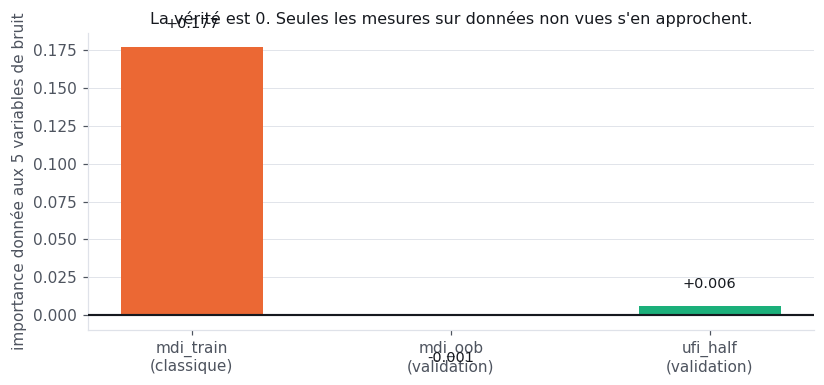

In [395]:
fig, ax = plt.subplots(figsize=(7.6, 3.6))
noms = ["mdi_train\n(classique)", "mdi_oob\n(validation)", "ufi_half\n(validation)"]
vals = [mesures[k][bruit].sum() for k in ("mdi_train", "mdi_oob", "ufi_half")]
b = ax.bar(noms, vals, color=[ORANGE, BLEU, VERT], width=.55, zorder=3)
ax.axhline(0, color=INK, lw=1.4, zorder=4)
for r_, v in zip(b, vals):
    ax.text(r_.get_x()+r_.get_width()/2, v + (.012 if v >= 0 else -.03),
            f"{v:+.3f}", ha="center", fontsize=9.5, color=INK)
ax.set_ylabel("importance donnée aux 5 variables de bruit")
ax.grid(axis="y")
ax.set_title("La vérité est 0. Seules les mesures sur données non vues s'en approchent.",
             fontsize=10.5, color=INK)
plt.tight_layout(); plt.show()

**Le remède fonctionne.** Le bruit passe d'une masse franchement positive à quelque chose
d'indiscernable de zéro.

### Mais sur quel arbre ? La nuance qui compte

Cet arbre a **800 feuilles pour 800 lignes** d'entraînement : un point par feuille, l'arbre
complet. Or c'est exactement la configuration que Scornet (2023) **interdit** :

> *« We therefore stress that MDI must **not** be computed using fully grown trees. »*

Comparer le remède hors-échantillon à un arbre complet, c'est donc le comparer à une pratique que
personne ne recommande. Refaisons la mesure en tronquant progressivement.

In [396]:
# meme protocole, en faisant varier la taille minimale des feuilles.
# On suit le BRUIT (cible 0) et le SIGNAL (cible sum I_j), pour les deux mesures.
tailles = (1, 5, 20, 50, 100, 200)
feuilles_msl = []
suivi = {m: {"bruit": [], "signal": []} for m in ("mdi_train", "mdi_oob")}

for msl in tailles:
    nb_ = []
    acc = {m: {"bruit": [], "signal": []} for m in suivi}
    for rep in range(30):
        g = np.random.default_rng(rep)
        Xa, ya = simulate.sample(scenario, 1500, g)
        ordre_r = g.permutation(1500)
        v_r, t_r = ordre_r[:500], ordre_r[500:]
        ctr = float(ya[t_r].mean())
        mod = models.grow(Xa[t_r], ya[t_r] - ctr, cfg, seed=rep, min_samples_leaf=msl)
        nb_.append(mod.mean_leaves)
        mesures_msl = mdi.all_measures(mod, Xa[v_r], ya[v_r] - ctr, d)
        for m in suivi:
            acc[m]["bruit"].append(mesures_msl[m][bruit].sum())
            acc[m]["signal"].append(mesures_msl[m][~bruit].sum())
    feuilles_msl.append(np.mean(nb_))
    for m in suivi:
        for q in ("bruit", "signal"):
            suivi[m][q].append(np.mean(acc[m][q]))

print(f"{'feuilles':>9} | {'BRUIT (cible 0)':>24} | {'SIGNAL (cible %.2f)' % verite.sum():>24}")
print(f"{'':>9} | {'mdi_train':>11} {'mdi_oob':>12} | {'mdi_train':>11} {'mdi_oob':>12}")
print("-" * 66)
for i_m in range(len(tailles)):
    print(f"{feuilles_msl[i_m]:>9.0f} | {suivi['mdi_train']['bruit'][i_m]:>+11.3f} "
          f"{suivi['mdi_oob']['bruit'][i_m]:>+12.3f} | "
          f"{suivi['mdi_train']['signal'][i_m]:>11.3f} {suivi['mdi_oob']['signal'][i_m]:>12.3f}")

 feuilles |          BRUIT (cible 0) |      SIGNAL (cible 1.08)
          |   mdi_train      mdi_oob |   mdi_train      mdi_oob
------------------------------------------------------------------
     1000 |      +0.178       -0.004 |       1.189        0.924
      161 |      +0.087       -0.004 |       1.116        0.924
       38 |      +0.012       -0.001 |       0.967        0.860
       15 |      +0.001       -0.001 |       0.851        0.790
        8 |      +0.000       +0.000 |       0.778        0.737
        4 |      +0.000       +0.000 |       0.684        0.665


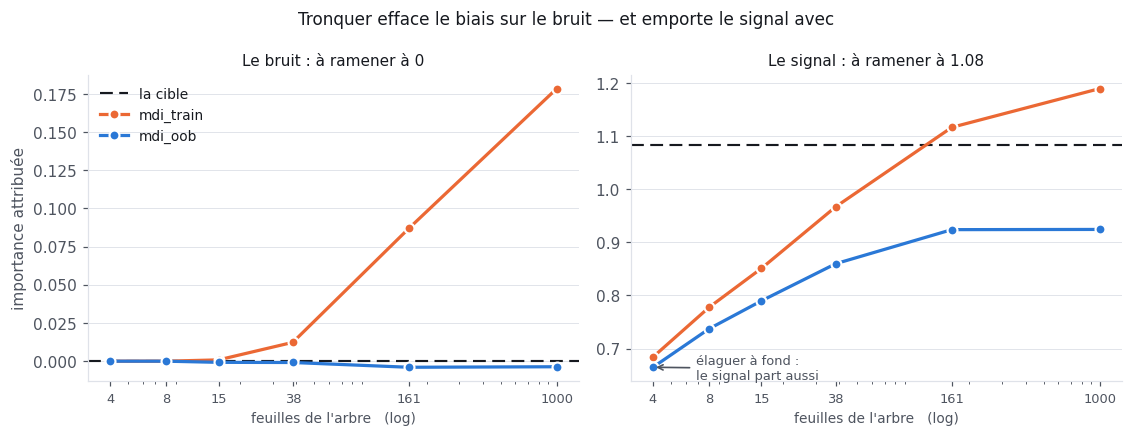

In [397]:
fig, (g_, d_) = plt.subplots(1, 2, figsize=(10.4, 4.0))

for ax, quoi, cible, titre in (
    (g_, "bruit", 0.0, "Le bruit : à ramener à 0"),
    (d_, "signal", float(verite.sum()), f"Le signal : à ramener à {verite.sum():.2f}"),
):
    ax.axhline(cible, color=INK, lw=1.4, ls=(0, (6, 3)), zorder=2, label="la cible")
    for m, coul in (("mdi_train", ORANGE), ("mdi_oob", BLEU)):
        ax.plot(feuilles_msl, suivi[m][quoi], marker="o", ms=6.5, lw=2.1, color=coul,
                mec="white", mew=1.4, label=m, zorder=3)
    ax.set_xscale("log")
    ax.set_xticks(feuilles_msl)
    ax.set_xticklabels([f"{v:.0f}" for v in feuilles_msl], fontsize=8.5)
    ax.set_xlabel("feuilles de l'arbre   (log)", fontsize=9)
    ax.set_title(titre, fontsize=10, color=INK)
    ax.grid(axis="y")

g_.set_ylabel("importance attribuée")
g_.legend(frameon=False, fontsize=9, loc="upper left")
d_.annotate("élaguer à fond :\nle signal part aussi",
            (feuilles_msl[-1], suivi["mdi_oob"]["signal"][-1]),
            textcoords="offset points", xytext=(28, -8), fontsize=8.5, color=SOFT,
            arrowprops=dict(arrowstyle="->", color=SOFT, lw=1.1))

fig.suptitle("Tronquer efface le biais sur le bruit — et emporte le signal avec",
             fontsize=11, color=INK)
plt.tight_layout(); plt.show()

---
## 9. Remède 2 : élaguer l'arbre

L'autre biais vient de la **profondeur**. Un arbre qui mémorise chaque point apprend le bruit.
**Élaguer**, c'est supprimer les coupures qui n'apprennent rien de réel.

Le projet utilise l'**alpha-trimming** (Surjanovic et al., 2024). À chaque nœud on se demande :
*les données justifient-elles statistiquement cette coupure ?* Le critère compare deux modèles —
une seule moyenne contre deux — et pénalise le second parce qu'il a plus de paramètres.

Un unique réglage $\alpha$ contrôle la sévérité : $\alpha = 0$ ne coupe rien, $\alpha$ grand élague
fort. Et surtout, **l'élagage se fait après la croissance** : un seul arbre construit suffit pour
toute la grille.

Ce qui le rend *adaptatif* : le gain d'une coupure grandit comme $|N|$, la pénalité seulement comme
$\log|N|$. Donc on élague **fort là où les données sont rares**, et peu là où elles sont nombreuses.

> **Le paramètre qui décide, d'après les auteurs eux-mêmes : le rapport signal/bruit.** Leur
> proposition 3.3 établit que le bon niveau d'élagage est une **fonction du SNR**, et que c'est à
> **bas SNR** que l'élagage paie le plus. L'intuition est directe : plus il y a de bruit, plus un
> arbre profond en absorbe, plus il y a à gagner à le raccourcir.
>
> C'est une condition à respecter pour que le test soit loyal. Évaluer la méthode uniquement à
> SNR élevé — là où elle n'est pas censée servir — produirait un résultat négatif sans valeur.
> Le protocole balaie donc $\mathrm{SNR} \in \{0{,}25,\ 1,\ 4\}$, et la conclusion tient aussi
> dans le régime qui leur est favorable : à SNR $= 0{,}25$ l'élagage devient **neutre** pour les
> mesures hors-échantillon (10 répétitions gagnantes sur 20, $p = 0{,}60$) — il cesse de nuire,
> sans jamais aider.

### Pourquoi c'est le cœur du projet

Les parties 1 à 8 sont du contexte. **C'est ici que se joue la question posée**, pour trois
raisons :

**1 · C'est la moitié du sujet.** La question posée porte sur un MDI calculé à la fois sur des
arbres **moins profonds** et sur un **jeu de validation**. Deux clauses, deux remèdes : la
validation (partie 8) et l'élagage (ici), par alpha-trimming.

**2 · Rien ne garantit que ça marche.** Les deux remèdes ne coûtent pas la même chose : mesurer sur
la validation laisse l'arbre intact, alors qu'élaguer **détruit du vrai signal** — le théorème 3 de
Scornet (2023) dit que le MDI converge vers $\text{Var}(f_j(X_j))$ quand la profondeur
$k \to \infty$, donc *plus profond est mieux en théorie*. Élaguer échange un biais contre un autre,
et le solde peut être négatif.

**3 · La combinaison est la contribution.** Les deux remèdes existent séparément ; personne n'a
testé leur conjonction. Soit ils attaquent des défauts **différents** et s'additionnent, soit ils
attaquent **le même** (le bruit absorbé par la profondeur) et ce sont des **substituts**.

La figure qui suit montre qu'un $\alpha$ optimal existe pour la **prédiction**. Toute la question
est de savoir s'il est au même endroit pour l'**importance** — la partie 12 y répond.

**Le vrai code**, encore une fois — l'algorithme 1 du papier Surjanovic–Henrey–Loughin, transcrit
dans `src/prune.py` avec ses commentaires :

In [398]:
import prune

print(inspect.getsource(prune.alpha_trim))

def alpha_trim(tree: TreeView, alpha: float) -> TreeView:
    """Return a pruned copy of `tree`. alpha = 0 returns it unchanged."""
    if alpha == 0.0:
        return tree

    children_left = tree.children_left.copy()
    children_right = tree.children_right.copy()
    feature = tree.feature.copy()
    weight = tree.weighted_n_node_samples
    node_sse = weight * tree.impurity

    n_nodes = feature.size
    information = np.zeros(n_nodes, dtype=np.float64)
    subtree_sse = node_sse.copy()
    is_terminal = tree.feature < 0

    # reverse construction order: scikit-learn numbers a node before its subtree,
    # so descending index order visits every child before its parent
    for node in range(n_nodes - 1, -1, -1):
        if tree.feature[node] < 0:
            continue
        left = int(children_left[node])
        right = int(children_right[node])
        count = float(weight[node])

        parent_information = _information(count, count * tree.impurity[node],
                  

### Les deux formules de l'article

**L'équation (4)** — ce que `_information()` calcule. C'est la **déviance** d'un nœud $N$ : moins
deux fois sa log-vraisemblance gaussienne, à $\hat\sigma^2$ donné.

$$I_N \;=\; |N| \,\log\!\big(2\pi\hat\sigma^2\big) \;+\; \frac{1}{\hat\sigma^2}\sum_{i \in N}\big(y_i - \mu_N\big)^2$$

C'est un **coût** : plus $I_N$ est **petit**, mieux le modèle décrit les données. Un nœud dont les
points sont loin de leur moyenne a donc une somme des carrés grande, donc un $I_N$ **grand** — un
mauvais ajustement, qui plaide *pour* la coupure.

**L'inégalité (5)** — la seule décision de tout l'algorithme. On **fusionne** (on supprime la
coupure) quand :

$$\underbrace{I_N + \alpha P_{0,|N|}}_{\text{une seule moyenne}} \;\;\leq\;\; \underbrace{I_{N_L} + I_{N_R} + \alpha P_{1,|N|}}_{\text{deux moyennes}}, \qquad P_{0,n} = 2\log n, \quad P_{1,n} = 5\log n$$

À gauche le modèle simple : une moyenne, deux paramètres $(\mu, \sigma^2)$, d'où $P_0 = 2\log n$.
À droite le modèle à deux moyennes : cinq paramètres $(\mu_1, \mu_2, \sigma^2$, et le point de
coupure$)$, d'où $P_1 = 5\log n$.

Le modèle de droite ajuste forcément mieux ($I_L + I_R \leq I_N$), mais il paie $3\alpha\log n$ de
plus. **Si le gain d'ajustement ne couvre pas ce surcoût, la coupure saute.**

Et l'accumulation, quand la coupure survit :

$$I_N \;\longleftarrow\; I_{N_L} + I_{N_R} + \alpha\big(P_{1,|N|} - P_{0,|N|}\big)$$

Le nœud transmet vers le haut le coût de tout ce qui est sous lui — c'est ce qui permet à une
branche entière d'être dissoute plus tard.

### Deux détails du code

- `for node in range(n_nodes - 1, -1, -1)` : on part des **feuilles** et on remonte. Scikit-learn
  numérote un nœud avant son sous-arbre, donc parcourir les indices à l'envers visite chaque enfant
  avant son parent — nécessaire, puisque $I_{N_L}$ et $I_{N_R}$ doivent être connus pour trancher
  sur $N$.
- la boucle `while stack` à la fin corrige un cas que l'article ne traite pas explicitement : un
  nœud peut survivre à l'inégalité (5) alors que **son parent** vient d'être fusionné plus haut —
  il faut alors le détacher aussi, sinon il reste compté bien qu'inatteignable depuis la racine.

Reste à définir **« erreur de prédiction »**, affichée plus bas : pour chaque maison de validation,
l'écart entre la prédiction et le vrai prix, mis au carré (pour que les écarts positifs et négatifs
ne s'annulent pas), moyenné sur toutes les maisons. C'est le **MSE** (*mean squared error*) :

$$\text{MSE} = \text{moyenne}\big((\hat{y}_i - y_i)^2\big)$$

Plus il est petit, mieux l'arbre prédit sur des données qu'il n'a jamais vues pour grandir.

In [399]:
base = models.grow(X_tr, y_tr, cfg, seed=0, min_samples_leaf=5)
grille = (0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 2.5, 3.0)

print(f"{'alpha':>6} {'feuilles':>9}   {'erreur de prédiction':>21}")
feuilles, erreurs = [], []
for a in grille:
    m = prune.trim(base, a)
    err = float(np.mean((m.predict(X_val) - y_val)**2))
    feuilles.append(m.mean_leaves); erreurs.append(err)
    print(f"{a:>6.2f} {m.mean_leaves:>9.0f}   {err:>21.4f}")

 alpha  feuilles    erreur de prédiction
  0.00       125                  0.6404
  0.25       125                  0.6404
  0.50       114                  0.6405
  0.75        93                  0.6441
  1.00        46                  0.5805
  1.50        17                  0.5633
  2.00         5                  0.6515
  2.50         4                  0.6573
  3.00         4                  0.6573


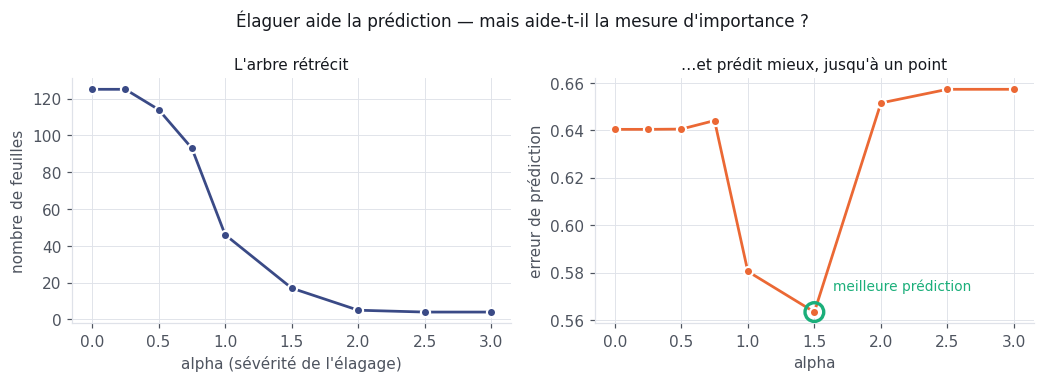

In [400]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.5))

axes[0].plot(grille, feuilles, marker="o", color=PRUNE, lw=1.8, ms=6,
             mec="white", mew=1.4, zorder=3)
axes[0].set_xlabel("alpha (sévérité de l'élagage)"); axes[0].set_ylabel("nombre de feuilles")
axes[0].set_title("L'arbre rétrécit", fontsize=10); axes[0].grid()

axes[1].plot(grille, erreurs, marker="o", color=ORANGE, lw=1.8, ms=6,
             mec="white", mew=1.4, zorder=3)
k = int(np.argmin(erreurs))
axes[1].scatter([grille[k]], [erreurs[k]], s=150, facecolor="none",
                edgecolor=VERT, lw=2.2, zorder=4)
axes[1].annotate("meilleure prédiction", (grille[k], erreurs[k]),
                 textcoords="offset points", xytext=(12, 14), fontsize=9, color=VERT)
axes[1].set_xlabel("alpha"); axes[1].set_ylabel("erreur de prédiction")
axes[1].set_title("…et prédit mieux, jusqu'à un point", fontsize=10); axes[1].grid()

fig.suptitle("Élaguer aide la prédiction — mais aide-t-il la mesure d'importance ?",
             fontsize=11, color=INK)
plt.tight_layout(); plt.show()

L'erreur descend puis remonte : il existe une quantité d'élagage optimale. **Pas assez d'élagage**
(alpha trop petit) laisse l'arbre apprendre le bruit ; **trop d'élagage** (alpha trop grand) lui
fait perdre du vrai signal.

Et c'est exactement la question du projet : **ce réglage optimal pour *prédire* est-il aussi le bon
pour *mesurer l'importance* ?** Rien ne l'impose.

---
## 10. Comment on sait qui a raison

Problème de méthode : sur des données réelles, **personne ne connaît la vraie importance**. On ne
peut donc pas dire si une mesure se trompe.

La solution : fabriquer un monde dont on connaît les règles.

$$y = f_1(x_1) + f_2(x_2) + \dots + \text{bruit}$$

On **choisit** les fonctions $f_j$, donc on peut calculer exactement la contribution de chaque
variable. C'est sa variance :

$$I_j = \text{Var}\big(f_j(x_j)\big)$$

L'intuition : *de combien cette variable fait-elle bouger $y$ ?* Une variable dont la contribution
ne bouge jamais ne distingue personne — importance nulle. Les variables de bruit ont $f_j = 0$,
donc $I_j = 0$ **exactement** : ce sont nos pièges.

Que ce soit la bonne cible est un théorème de Scornet (2023), valable quand le modèle est additif
et les variables indépendantes.



### Les scénarios disponibles

Tous additifs à variables indépendantes — la seule situation où $I_j$ existe. Chacun isole une
difficulté différente :

| | $n$ | $d$ | signaux | bruit | **ce qu'il met à l'épreuve** |
|---|---|---|---|---|---|
| `S1` | 1000 | 10 | 5 | 50 % | **Le contrôle.** Les cinq vraies variables sont largement au-dessus du bruit, et il y a autant de signal que de bruit. N'importe quelle mesure correcte doit réussir — donc tout échec ici dénonce un défaut de la mesure, pas une difficulté du problème. C'est aussi le seul scénario assez petit pour qu'on imprime les dix importances et qu'on les lise à l'œil. |
| `DS1` | 800 | 50 | 2 | 96 % | **La parcimonie.** Deux aiguilles dans cinquante colonnes. Chaque colonne inutile est une occasion supplémentaire de tomber par hasard sur une coupure qui « marche » sur l'entraînement : le biais devrait donc grandir avec $d$, à signal constant. |
| `DS3` | 600 | 100 | 4 | 96 % | **La même question, deux fois plus large**, et avec moins de lignes. `DS1` et `DS3` ne diffèrent que par là, ce qui isole l'effet de la dimension sans changer la nature du signal. |
| `DS4` | 600 | 100 | 4 | 96 % | **Le scénario discriminant.** Mêmes $n$ et $d$ que `DS3`, mais des contributions très inégales. C'est celui qui sépare le mieux les trois mesures une fois le SNR abaissé — c'est sur lui qu'on mesure le résultat de la partie 12. |
| `DS6` | 500 | 30 | 10 | 67 % | **La symétrie.** Les dix signaux ont *exactement* la même importance ($0{,}25$), donc une mesure correcte doit les déclarer égaux. Un arbre unique en est incapable : la dispersion entre les dix estimations atteint **57 %**, contre **30 %** pour une forêt de 100. C'est le seul scénario qui sépare ce que coûte *un arbre* de ce qu'apporte *une forêt*. |
| `DS8` | 500 | **1000** | 4 | 100 % | **Le régime $d > n$.** Deux fois plus de colonnes que de lignes, et 996 d'entre elles sont du bruit pur. C'est le cas extrême de la parcimonie, celui où l'arbre a le plus d'occasions de se tromper — et le plus coûteux à faire tourner (6,2 s par répétition). |

La colonne **bruit** est la part des colonnes dont la vraie importance vaut exactement zéro. Elle
passe de 50 % à 100 %, ce qui est le principal axe de variation entre les scénarios : `S1` teste
une mesure dans des conditions confortables, les `DS` la testent là où presque tout est du bruit.

`S1` est écrit pour ce projet, dans le cadre du Modèle 3 de Scornet (2023) : $X$ uniforme sur
$[0,1]^d$, contributions additives, bruit gaussien. Il sert de **contrôle** — un problème assez
facile pour que tout échec soit imputable à la mesure, et assez petit ($d = 10$) pour qu'on puisse
imprimer les dix importances et les lire.

Le SNR est réglable sur **tous** les scénarios, `DS` compris : `simulate.duroux(tag, snr=...)`.
C'est le levier principal du protocole, et la remarque ci-dessous dit pourquoi.

Les cinq suivants viennent de **Duroux & Scornet (2016)**, section 4. Ils couvrent un régime que
`S1` n'atteint pas : jusqu'à **100 % de bruit** et $d = 1000$ pour $n = 500$. C'est là
que le biais devrait frapper le plus fort — plus il y a de colonnes candidates, plus l'arbre a
d'occasions de tomber par chance sur une coupure de bruit qui « marche ».

> **Trois des huit modèles du papier sont inutilisables ici.** Les modèles 2, 5 et 7 contiennent
> des produits ($\tilde{X}_1\tilde{X}_2$) et des indicatrices à plusieurs variables. Dans ces cas,
> $\mathrm{Var}(f_j(X_j))$ n'est la MDI de population d'**aucun** arbre — il n'y a donc pas de
> vérité contre laquelle mesurer un biais. Le code les refuse explicitement.

In [401]:
print(f"{'variable':>12} {'fonction':>14} {'I_j (vérité)':>13}")
for j, c in enumerate(scenario.components):
    print(f"{('bruit' if bruit[j] else 'signal'):>7} {j+1:<4} {c.name:>14} {c.variance:>13.4f}")

explicable = verite.sum()
print(f"\n  variance explicable  sum(I_j) : {explicable:.4f}")
print(f"  variance du bruit    sigma^2  : {scenario.sigma**2:.4f}")
print(f"  variance totale de y          : {explicable + scenario.sigma**2:.4f}")
print(f"  vérifiée sur l'échantillon    : {y_all.var():.4f}")

    variable       fonction  I_j (vérité)
 signal 1            linear        0.0833
 signal 2              sine        0.5000
 signal 3         quadratic        0.0889
 signal 4              step        0.2500
 signal 5              bump        0.1600
  bruit 6             noise        0.0000
  bruit 7             noise        0.0000
  bruit 8             noise        0.0000
  bruit 9             noise        0.0000
  bruit 10            noise        0.0000

  variance explicable  sum(I_j) : 1.0822
  variance du bruit    sigma^2  : 0.2706
  variance totale de y          : 1.3528
  vérifiée sur l'échantillon    : 1.3591


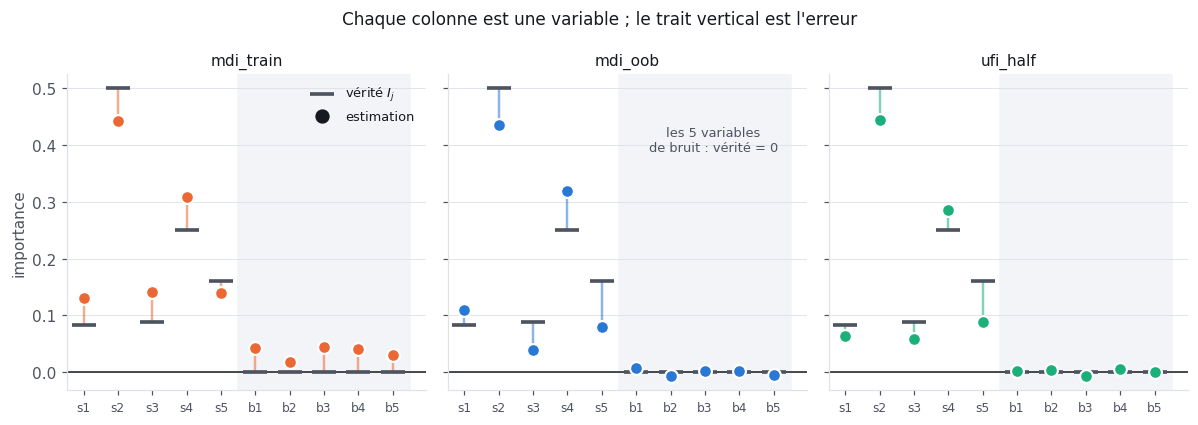

In [402]:
# Une colonne par variable. La barre grise est la VERITE, le point colore ce que
# la mesure annonce : le trait vertical entre les deux EST l'erreur.
fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.9), sharey=True)
pos = np.arange(d)
etiquettes = [f"s{j+1}" if not bruit[j] else f"b{j-4}" for j in range(d)]

for ax, (nom, coul) in zip(axes, [("mdi_train", ORANGE), ("mdi_oob", BLEU),
                                  ("ufi_half", VERT)]):
    ax.axvspan(4.5, d - 0.5, color="#f3f4f7", zorder=0)           # zone de bruit
    ax.axhline(0, color=INK, lw=1.0, zorder=2)
    est = mesures[nom]
    ax.vlines(pos, verite, est, color=coul, lw=1.6, alpha=.55, zorder=3)
    ax.scatter(pos, verite, marker="_", s=240, color=SOFT, lw=2.4, zorder=4)
    ax.scatter(pos, est, s=70, color=coul, zorder=5, edgecolor="white", lw=1.4)
    ax.set_xticks(pos); ax.set_xticklabels(etiquettes, fontsize=8)
    ax.set_title(nom, fontsize=10, color=INK)
    ax.grid(axis="y")

axes[0].set_ylabel("importance")
axes[1].text(7.25, verite.max()*.78, "les 5 variables\nde bruit : vérité = 0",
             ha="center", fontsize=8.5, color=SOFT)
axes[0].scatter([], [], marker="_", s=240, color=SOFT, lw=2.4, label="vérité $I_j$")
axes[0].scatter([], [], s=70, color=INK, label="estimation")
axes[0].legend(frameon=False, fontsize=8.5, loc="upper right")
fig.suptitle("Chaque colonne est une variable ; le trait vertical est l'erreur",
             fontsize=11, color=INK)
plt.tight_layout(); plt.show()

**Comment lire la figure.** Les 10 variables sont alignées en abscisse : `s1`…`s5` portent du
signal, `b1`…`b5` sont du bruit pur (fond grisé). Pour chacune :

- le **tiret gris** est la vérité $I_j$ — pour les cinq variables de bruit il est posé sur zéro ;
- le **point coloré** est ce que la mesure annonce ;
- le **trait vertical** qui les relie **est l'erreur**. Plus il est court, meilleure est la mesure.

Et le verdict se lit en un coup d'œil :

- **dans la zone grisée**, `mdi_train` (orange) flotte nettement au-dessus de zéro : il invente de
  l'importance. `mdi_oob` et `ufi_half` y ont des traits presque invisibles ;
- **sur les variables de signal**, c'est l'inverse : les traits orange sont courts, les bleus et
  verts plus longs et dirigés vers le bas — ils sous-estiment.

Chaque mesure est donc juste là où l'autre se trompe. C'est exactement pourquoi un seul chiffre
résumé ne suffit jamais à départager, et pourquoi l'analyse garde `noise_mass` et `signal_mass`
séparés.

---
## 12. Ce qu'on a trouvé

> **Partie en cours de rédaction.** Le protocole de la partie 11 est arrêté et implémenté ; les
> runs tournent.

**La question posée est celle-ci :** l'élagage adaptatif **plus** le calcul du MDI sur un jeu de
validation fait-il mieux que le calcul sur validation **seul** — et mieux que la pratique
courante ? C'est ce que les comparaisons appariées de la partie 11 doivent trancher, et les
chiffres ne sont pas encore consolidés.

### Un premier aperçu sur `S1`

Trois façons de mesurer l'importance, sur les mêmes données, 20 répétitions.

In [403]:
grille_a = (0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0)
R = 20
err_pred, nb_feuilles = [], []
err_imp = {m: [] for m in mdi.MEASURES}

for a in grille_a:
    p_, f_ = [], []
    e_ = {m: [] for m in mdi.MEASURES}
    for rep in range(R):
        g = np.random.default_rng(rep)
        Xa, ya = simulate.sample(scenario, 1000, g)
        Xtest, ytest = simulate.sample(scenario, 4000, g)
        ordre_a = g.permutation(1000)
        v_a, t_a = ordre_a[:333], ordre_a[333:]
        ctr = float(ya[t_a].mean())
        mod = prune.trim(models.grow(Xa[t_a], ya[t_a] - ctr, cfg, seed=rep,
                                     min_samples_leaf=5), a)
        p_.append(np.mean((mod.predict(Xtest) - (ytest - ctr))**2))
        f_.append(mod.mean_leaves)
        for m, v in mdi.all_measures(mod, Xa[v_a], ya[v_a] - ctr, d).items():
            e_[m].append(((v - verite)**2).sum())
    err_pred.append(np.mean(p_)); nb_feuilles.append(np.mean(f_))
    for m in mdi.MEASURES:
        err_imp[m].append(np.mean(e_[m]))

k_pred = int(np.argmin(err_pred))
k_imp = {m: int(np.argmin(err_imp[m])) for m in mdi.MEASURES}

print(f"{'alpha':>6} {'feuilles':>9} {'PRÉDICTION':>12} | "
      + " ".join(f"{m:>11}" for m in mdi.MEASURES))
print("-" * 73)
for i_a, a in enumerate(grille_a):
    marque = ("   <- alpha*" if i_a == k_pred else "")
    for m in mdi.MEASURES:
        if k_imp[m] == i_a:
            marque += f"   <- alpha'({m})"
    print(f"{a:>6.2f} {nb_feuilles[i_a]:>9.0f} {err_pred[i_a]:>12.4f} | "
          + " ".join(f"{err_imp[m][i_a]:>11.5f}" for m in mdi.MEASURES) + marque)

print(f"\nalpha* (prédiction) = {grille_a[k_pred]}")
for m in mdi.MEASURES:
    print(f"alpha' ({m:<9}) = {grille_a[k_imp[m]]}")

 alpha  feuilles   PRÉDICTION |   mdi_train     mdi_oob    ufi_half
-------------------------------------------------------------------------
  0.00       107       0.7332 |     0.01697     0.01879     0.01577
  0.25       107       0.7332 |     0.01697     0.01879     0.01575   <- alpha'(ufi_half)
  0.50        98       0.7284 |     0.01669     0.01858     0.01578   <- alpha'(mdi_oob)
  0.75        71       0.6966 |     0.01637     0.01978     0.01707   <- alpha'(mdi_train)
  1.00        37       0.6511 |     0.01683     0.02378     0.02061
  1.25        20       0.6447 |     0.02298     0.03061     0.02755   <- alpha*
  1.50        10       0.6630 |     0.03257     0.03802     0.03625
  2.00         6       0.7010 |     0.04441     0.04653     0.04623
  2.50         4       0.7130 |     0.04905     0.05014     0.04987
  3.00         4       0.7139 |     0.04911     0.05017     0.04996

alpha* (prédiction) = 1.25
alpha' (mdi_train) = 0.75
alpha' (mdi_oob  ) = 0.5
alpha' (ufi_half ) = 

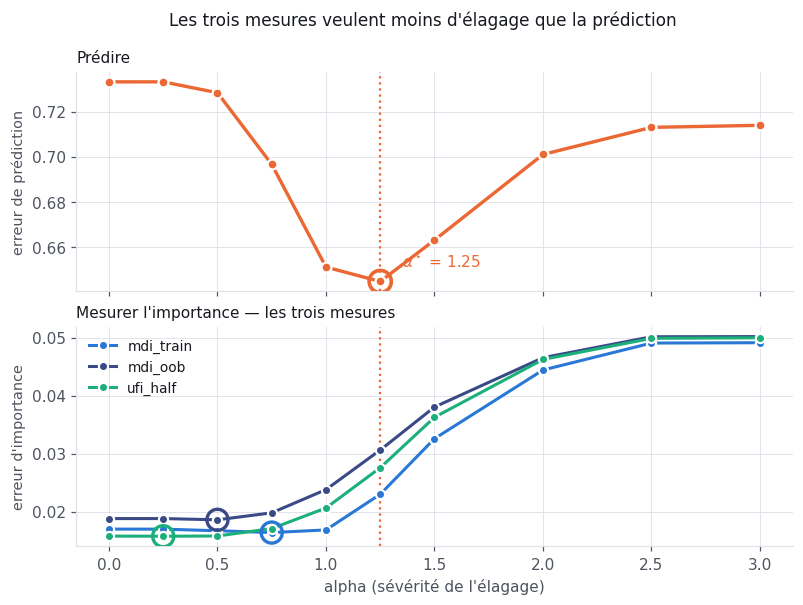

In [404]:
fig, (haut, bas) = plt.subplots(2, 1, figsize=(8.4, 5.6), sharex=True,
                                gridspec_kw={"hspace": 0.16})

haut.plot(grille_a, err_pred, marker="o", color=ORANGE, lw=2.2, ms=6.5, mec="white",
          mew=1.5, zorder=3)
haut.scatter([grille_a[k_pred]], [err_pred[k_pred]], s=210, facecolor="none",
             edgecolor=ORANGE, lw=2.4, zorder=4)
haut.set_ylabel("erreur de prédiction", fontsize=9.5)
haut.set_title("Prédire", fontsize=10, color=INK, loc="left")
haut.annotate(f"$\\alpha^\\star$ = {grille_a[k_pred]}", (grille_a[k_pred], err_pred[k_pred]),
              textcoords="offset points", xytext=(14, 10), fontsize=10, color=ORANGE)

for m, coul in (("mdi_train", "#2a78d6"), ("mdi_oob", PRUNE), ("ufi_half", VERT)):
    bas.plot(grille_a, err_imp[m], marker="o", color=coul, lw=2.0, ms=6, mec="white",
             mew=1.4, label=m, zorder=3)
    bas.scatter([grille_a[k_imp[m]]], [err_imp[m][k_imp[m]]], s=190, facecolor="none",
                edgecolor=coul, lw=2.2, zorder=4)
bas.set_ylabel("erreur d'importance", fontsize=9.5)
bas.set_title("Mesurer l'importance — les trois mesures", fontsize=10, color=INK, loc="left")
bas.legend(frameon=False, fontsize=9, loc="upper left")

for ax in (haut, bas):
    ax.axvline(grille_a[k_pred], color=ORANGE, ls=":", lw=1.5, zorder=1)
    ax.grid()
bas.set_xlabel("alpha (sévérité de l'élagage)")
fig.suptitle("Les trois mesures veulent moins d'élagage que la prédiction",
             fontsize=11, color=INK)
plt.tight_layout(); plt.show()

### Le pari est perdant d'avance

Reprenons le tableau en ne gardant que ce qui décide : ce qu'on peut gagner en élaguant au mieux,
et ce qu'on perd au réglage que la validation croisée choisit réellement.

| mesure | à $\alpha = 0$ | au mieux | **gain maximal** | à $\alpha^{\star} = 1{,}25$ | **perte réelle** |
|---|---|---|---|---|---|
| `mdi_train` | $0{,}01697$ | $0{,}01637$ | $-3{,}5\,\%$ | $0{,}02298$ | $\mathbf{+35\,\%}$ |
| `mdi_oob` | $0{,}01879$ | $0{,}01858$ | $-1{,}1\,\%$ | $0{,}03061$ | $\mathbf{+63\,\%}$ |
| `ufi_half` | $0{,}01577$ | $0{,}01575$ | $-0{,}1\,\%$ | $0{,}02755$ | $\mathbf{+75\,\%}$ |

**Le meilleur élagage possible ne rapporte presque rien** — $0{,}1$ à $3{,}5\,\%$, et encore
faut-il connaître $I_j$ pour le trouver. La colonne de gauche du tableau est quasi plate entre
$\alpha = 0$ et $\alpha'$.

**Le réglage réel coûte 35 à 75 %.** Et ce n'est pas un réglage absurde : c'est exactement
l'optimum de prédiction, celui que la validation croisée est faite pour trouver.

> **La réponse tient en une phrase : il n'y a pas lieu d'élaguer pour mesurer l'importance.** On
> risque $35$ à $75\,\%$ pour gagner au mieux $1\,\%$. Et contrairement au protocole complet, ça se
> lit ici sur **une seule grille et un seul scénario**.

### Deux détails qui expliquent pourquoi

**L'ordre des $\alpha'$ n'est pas un hasard** : $0{,}75$ pour `mdi_train`, $0{,}50$ pour
`mdi_oob`, $0{,}25$ pour `ufi_half`. Plus une mesure corrige déjà le biais de profondeur, moins
elle réclame d'élagage — l'élagage et la mesure hors-échantillon retirent **la même chose**, donc
celle qui a déjà retiré n'a plus besoin de l'autre. C'est la thèse des substituts, lisible en une
colonne.

**Et `ufi_half` est le cas limite** : gain le plus faible ($0{,}1\,\%$) et perte la plus forte
($75\,\%$). Cohérent — c'est elle qui corrige le mieux, donc il ne lui reste rien à gagner, mais
elle paie quand même le prix de l'élagage en résolution perdue.

La raison de fond : l'erreur de prédiction est dominée par les gros signaux, alors que l'erreur
d'importance somme $\sum_j (\hat{I_j} - I_j)^2$ **à poids égal sur les dix variables**. Un élagage
sévère sacrifie les signaux faibles — indolore pour prédire, ruineux pour mesurer.

**Pourquoi ça conditionne la réponse à la question centrale.** La validation croisée ne sait
trouver que $\alpha^{\star}$ : elle n'a pas accès à $I_j$. Donc même si l'élagage améliorait le
MDI-oob, le seul réglage disponible en pratique irait le chercher au mauvais endroit — et un
résultat négatif ne voudrait pas dire « l'élagage ne sert à rien », mais « on ne sait pas le
régler ». Les bras `oracle` de la partie 11 existent pour départager les deux.